# Bounded YAML prompt improvement

English (primary) | [Español](prompt-search.es.ipynb) | [Case](README.es.md) | [Definitions and modeling](README.es.md#modelamiento)

**Status: one live OpenAI run recorded.** This notebook changes the policy prompt of a synthetic
debt assistant. The model, runtime, optimizer and evaluator stay fixed. No recursive improvement is claimed. Both languages replay the same [measured run](README.es.md#resultados-registrados).

The assistant seeks the largest feasible debt among 200, 300 and 600, in one or two payments,
with explicit consent. It generates one next-turn response from each fixed history.

**Recorded outcome:** no candidate accepted. Baseline validation: 75.0%; highest candidate score: 83.3%, with one violation. The token guard stopped the search after 148 calls and 83,815 tokens (estimated USD 0.10261125). Final testing was not reached.

The [Spanish guide](README.es.md) now combines the case, objective, model and results. Recorded outputs use protocol v2 and the original English objective; future live runs use v3 with the Spanish objective. This documentation change does not rerun the experiment.


## 1. Local environment

Follow [local setup](README.es.md#ejecución), install `requirements.txt`, select the kernel,
and fill the ignored `.env` from [.env.example](.env.example). Never put a key in a cell.
The default path replays the saved report. No package installation or API call happens automatically.


In [1]:
LANGUAGE = 'en'
from pathlib import Path
import importlib.util
import json
import sys
import difflib
from pprint import pformat
from html import escape
import yaml
from dotenv import load_dotenv
from IPython.display import Markdown, HTML, display

relative = Path("research/proposals/case-0003-debt-negotiation")
CASE = next((base / relative for base in [Path.cwd(), *Path.cwd().parents]
             if (base / relative / "prompt_search.py").is_file()), None)
if CASE is None:
    raise RuntimeError("Open this notebook inside the thinking-harness checkout")
spec = importlib.util.spec_from_file_location("case3_search", CASE / "prompt_search.py")
search = importlib.util.module_from_spec(spec)
sys.modules[spec.name] = search
spec.loader.exec_module(search)
load_dotenv(CASE / ".env", override=False)  # Never display credentials.

def text(en, es):
    return es if LANGUAGE == "es" else en

def block(value):
    rendered = value if isinstance(value, str) else pformat(value, width=100, sort_dicts=False)
    display(HTML('<pre style="white-space:pre-wrap;overflow-wrap:anywhere">' + escape(rendered) + "</pre>"))

cases = search.load_cases()
seed = yaml.safe_load((CASE / "prompt.yaml").read_text())
search.get_prompt(seed)
settings = yaml.safe_load((CASE / "config.yaml").read_text())
config = search.Config(**settings)
config.validate()
print(text("Local inputs loaded. No API calls.", "Entradas locales cargadas. Sin llamadas a la API."))

Local inputs loaded. No API calls.


## 2. Policy and golden set

[prompt.yaml](prompt.yaml) is the mutable policy; [golden-set.yaml](golden-set.yaml) contains
18 synthetic examples. [Objective section](README.es.md#objetivo) fixes allowed behavior. The optimizer sees
only development data. Validation selects candidates; final test stays outside the loop.

A capacity of 170 permits B in two payments of 150. C in two payments of 300 is infeasible.
The gap `installment - capacity` is a derived feature. Designing these inputs and outputs is
system modeling. The runtime does not train weights or compare literal reference strings.


In [2]:
print(text("Initial YAML policy", "Política YAML inicial"))
block((CASE / "prompt.yaml").read_text())
print(text("Synthetic partitions", "Particiones sintéticas"))
block({split: sum(c["split"] == split for c in cases)
       for split in ("development", "validation", "test")})
example = next(c for c in cases if c["id"] == "development-limited")
print(text("One golden example (labels are evaluator-only)",
           "Ejemplo del golden set (etiquetas exclusivas del evaluador)"))
block(yaml.safe_dump(example, sort_keys=False, allow_unicode=True))
print(text("Actual negotiator input", "Entrada efectiva del negociador"))
block(yaml.safe_dump(search.visible(example), sort_keys=False, allow_unicode=True))

Initial YAML policy


Synthetic partitions


One golden example (labels are evaluator-only)


Actual negotiator input


## 3. Protocol and budget

A response succeeds when its decision matches the reference, it violates no rule, and a fixed
LLM judge confirms consistency, relevance and clarity. Score is successful replies divided by
all evaluated replies. Select only zero-violation candidates with at least `min_gain` improvement.
This is discrete search, not gradient descent. The model judge still needs calibration.

`p000` is the generic seed. `p001` is the one-shot baseline generated from the objective and
development examples. Later versions change only the YAML `prompt` field. A baseline already
at target needs no iteration. The seed is not the final comparison baseline.

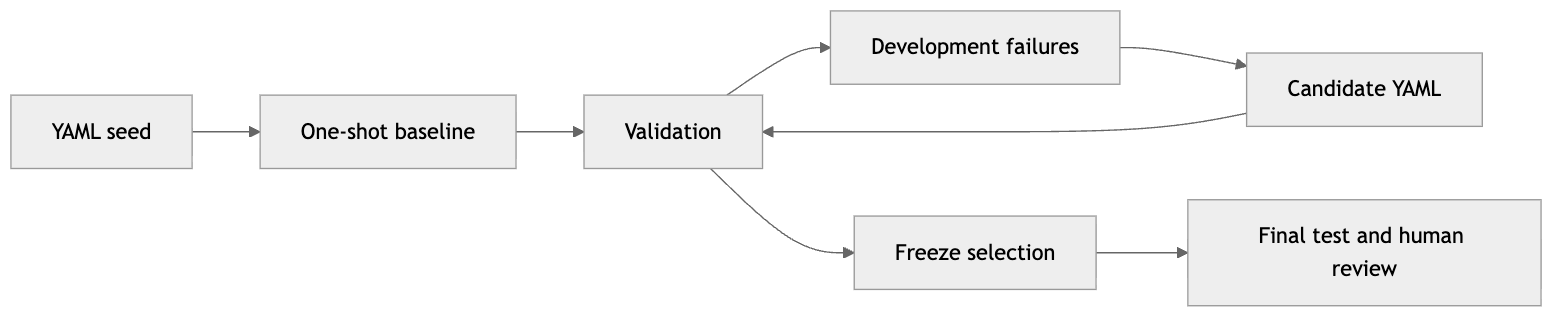

```mermaid
flowchart LR
    S[YAML seed] --> B[One-shot baseline]
    B --> V[Validation]
    V --> D[Development failures]
    D --> C[Candidate YAML]
    C --> V
    V --> F[Freeze selection]
    F --> T[Final test and human review]
```

The embedded preview is rendered from the Mermaid source above. Regenerate it after diagram edits.
The common cost guard includes all roles and final testing. It is an estimate, not a provider
billing cap. Review [config.yaml](config.yaml); live mode requires two explicit switches.


In [3]:
RUN_LIVE = False
REPLAY_REPORT = "results/20261017T011558Z-f5eca942/report.json"  # Saved live evidence; no API calls.

# Both this switch and config.yaml allow_live must be true for a charged run.
print(text("Configured bounds", "Límites configurados"))
block(settings)
counts = {s: sum(c["split"] == s for c in cases) for s in ("development", "validation", "test")}
upper_calls = (1 + 2 * counts["validation"] * config.evaluation_repeats
    + config.max_iterations * (2 * counts["development"] * config.evaluation_repeats
        + config.candidates_per_iteration * (1 + 2 * counts["validation"] * config.evaluation_repeats))
    + 4 * counts["test"] * config.evaluation_repeats)
print(text("Maximum scheduled calls before early stops:", "Máximo de llamadas antes de paradas anticipadas:"), upper_calls)
print(text("The common budget may stop the run before final testing.",
           "El presupuesto común puede detener la ejecución antes de la prueba final."))

Configured bounds


Maximum scheduled calls before early stops: 295
The common budget may stop the run before final testing.


## 4. Execute once or replay

The committed notebook replays saved evidence by default. To authorize another charged run,
clear `REPLAY_REPORT`, enable `allow_live` in config.yaml and set `RUN_LIVE = True`. Execution
writes evidence after each stage; following cells present it step by step.


In [4]:
report = None
if RUN_LIVE and REPLAY_REPORT:
    raise ValueError("Choose live execution OR replay, not both")
if RUN_LIVE:
    # Fresh charged run each time this cell executes. No automatic retries.
    report = search.run_search(config)
    report_path = Path(report["evidence_dir"]) / "report.json"
    print(text("Replay path:", "Ruta para volver a mostrar el reporte:"), report_path.relative_to(CASE))
elif REPLAY_REPORT:
    report_path = (CASE / REPLAY_REPORT).resolve()
    if not report_path.is_relative_to(CASE.resolve()):
        raise ValueError("Use a report inside the case folder")
    report = json.loads(report_path.read_text())
    if report.get("protocol") not in search.REPLAY_PROTOCOLS or report.get("mode") != "live":
        raise ValueError("Expected a live report from this protocol, not a test double")
    # Replay uses saved evidence, never current settings or a new API call.
    print(text("Replaying saved evidence. No API calls.", "Lectura de evidencia guardada. Sin llamadas a la API."))
else:
    print(text("NOT RUN. Add the local API key and review the configuration before enabling live mode.",
               "SIN EJECUTAR. Completar la clave local y revisar la configuración antes de activar el modo real."))

Replaying saved evidence. No API calls.


## 5. Every YAML version and decision

Show the seed, baseline and all proposed candidates, including duplicates and rejections.
A pending candidate is not a completed evaluation. Parent differences show what changed.


In [5]:
if report is None:
    print(text("Prompt versions and decisions will appear after a real run.",
               "Las versiones y decisiones aparecerán después de una ejecución real."))
else:
    # Prompt contents are shown as escaped text, not executable notebook content.
    header = text("| Version | Validation score | Violations | Retained at end |", "| Versión | Puntaje de validación | Incumplimientos | Conservada al terminar |")
    table = [header, "|---|---:|---:|---|"]
    measured = [(report.get("initial_version"), report.get("initial_validation"))]
    measured += [(e["version"], e["validation"]) for e in report["events"] if "validation" in e]
    for version_id, result in measured:
        if result is not None:
            retained = version_id == report.get("selected_version")
            table.append(f"| {version_id} | {result['score']:.1%} | {result['violations']} | {retained} |")
    display(Markdown("\n".join(table)))
    version_map = {v["id"]: v for v in report["versions"]}
    for version in report["versions"]:
        display(Markdown("### " + version["id"] + " | " + version["stage"]))
        print(text("Parent:", "Versión padre:"), version["parent"])
        saved = report_path.parent / version["path"]
        actual_hash = search.hashlib.sha256(saved.read_bytes()).hexdigest()
        if actual_hash != version["sha256"]:
            raise ValueError("Saved YAML hash differs from the run manifest")
        block(saved.read_text())
        parent = version_map.get(version["parent"])
        if parent:
            diff = difflib.unified_diff(parent["prompt"].splitlines(), version["prompt"].splitlines(),
                                        fromfile=parent["id"], tofile=version["id"], lineterm="")
            block("\n".join(diff) or text("No content change", "Sin cambio de contenido"))
        if version["id"] == report.get("initial_version"):
            result = report.get("initial_validation")
            block({"baseline_validation": None if result is None else
                   {k: result[k] for k in ("score", "violations")}})
        event = next((e for e in report["events"] if e.get("version") == version["id"]), None)
        if event:
            block({k: event[k] for k in ("iteration", "candidate", "status", "selected")})
            if "validation" in event:
                block({k: event["validation"][k] for k in ("score", "violations")})
        print(text("Selected at end:", "Seleccionada al terminar:"),
              version["id"] == report.get("selected_version"))

| Version | Validation score | Violations | Retained at end |
|---|---:|---:|---|
| p001 | 75.0% | 1 | True |
| p002 | 75.0% | 2 | False |
| p003 | 66.7% | 2 | False |
| p004 | 83.3% | 1 | False |

### p000 | seed

Parent: None


Selected at end: False


### p001 | one_shot_baseline

...

Parent: p001


Selected at end: False


### p004 | candidate

Parent: p001


Selected at end: False


## 6. Feedback and responses

Inspect development feedback, validation replies and the final comparison. Reference replies
are examples, not required wording. Responses remain in their original language in both notebooks.


In [6]:
if report is not None:
    def show_evaluation(label, result):
        display(Markdown("### " + label))
        if result is None:
            print(text("Incomplete or not reached", "Incompleto o no alcanzado"))
            return
        block({k: result[k] for k in ("score", "violations")})
        # Show every reply and judge rationale, not only the aggregate score.
        for row in result["rows"]:
            block({"case": row["id"], "repeat": row["repeat"], "success": row["success"],
                   "history": row["context"]["history"], "reply": row["reply"],
                   "checks": row["checks"], "judge": row["judge"]})

    show_evaluation(text("Baseline validation", "Validación del baseline"), report.get("initial_validation"))
    for event in report["events"]:
        if "development" in event:
            show_evaluation(text("Development feedback, round ", "Errores de desarrollo, ronda ")
                            + str(event["iteration"]), event["development"])
        elif "validation" in event:
            show_evaluation(text("Candidate validation ", "Validación del candidato ")
                            + event["version"], event["validation"])
    show_evaluation(text("Final test: baseline", "Prueba final: baseline"), report.get("final_initial"))
    show_evaluation(text("Final test: selected", "Prueba final: seleccionada"), report.get("final_selected"))

### Baseline validation

### Development feedback, round 1

### Candidate validation p002

### Candidate validation p003

### Development feedback, round 2

### Candidate validation p004

### Final test: baseline

Incomplete or not reached


### Final test: selected

Incomplete or not reached


## 7. Result and review

Report the stop reason, consumption, version lineage and final comparison without inferring
significance from a small synthetic set. Final-test feedback never returns to the optimizer.


In [7]:
if report is not None:
    block({"mode": report["mode"], "protocol": report["protocol"],
           "initial_version": report.get("initial_version"),
           "selected_version": report.get("selected_version"),
           "stop_reason": report["stop_reason"], "final_complete": report["final_complete"],
           "usage": report.get("usage")})
    if report["final_complete"]:
        delta = report["final_selected"]["score"] - report["final_initial"]["score"]
        print(text("Observed final score difference:", "Diferencia observada del puntaje final:"), delta)
        print(text("This small synthetic comparison does not establish statistical or real-world improvement.",
                   "Esta comparación sintética pequeña no demuestra mejora estadística ni efectividad real."))
    else:
        print(text("Final comparison incomplete; do not claim improvement.",
                   "Comparación final incompleta; no afirmar una mejora."))
    print(text("Saved configuration and source hashes", "Configuración y hashes de la ejecución"))
    block({"config": report["config"], "source_hashes": report["source_hashes"],
           "git_commit": report["git_commit"]})

Final comparison incomplete; do not claim improvement.
Saved configuration and source hashes


## Next step

Review the [run summary](README.es.md#resultados-registrados), prompt versions and evaluator decisions.
These outputs replay one live run. `.env` and raw request logs remain local. Further experiments
require a new protocol decision and a budget for final testing, which was not reached.
Return to [modeling](README.es.md#modelamiento), the [case](README.es.md), or the [Spanish notebook](prompt-search.es.ipynb).
